<a href="https://colab.research.google.com/github/Daood-Analyst/ice-hockey-match-analytics/blob/main/Ice_Hockey_Match_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ice Hockey Match Analytics & Winner Prediction
**End-to-end data analytics and machine learning project**

This notebook explores historical ice hockey match results, visualizes scoring patterns, builds pre-match team-form features, and compares machine-learning models for predicting whether the **home team wins**.

> **Important:** This is a historical-data demonstration, not a betting system or a guarantee of future outcomes. Predictions are uncertain and depend on data quality and whether the future competition resembles the historical data.

## 1. Project objectives
- Inspect and clean the match dataset.
- Explore goals, seasons, teams, and match outcomes.
- Engineer pre-match features using only each team's earlier games.
- Compare Logistic Regression and Random Forest using a chronological holdout.
- Evaluate accuracy, precision, recall, F1-score, ROC-AUC (where available), and a confusion matrix.
- Summarize limitations and next steps.

In [12]:
# If running in Google Colab, upload "Ice Hockey Dataset.xlsx" when prompted.
# If the file is already in the current working directory, it will be loaded directly.
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

file_path = Path("Ice Hockey Dataset.xlsx")
if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = Path(next(iter(uploaded.keys())))
    except ImportError:
        raise FileNotFoundError(
            "Place 'Ice Hockey Dataset.xlsx' beside this notebook, then run again."
        )

df = pd.read_excel(file_path, sheet_name=0)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 9,282 rows × 30 columns


,DATE,DAY,MONTH,YEAR,SEASON,HOMETEAM,AWAYTEAM,WINNER,HG,AG,...,HGOT,AGOT,HGSO,AGSO,TOTALOT,TOTALMAIN,TOTALFULL,TOTALHMAIN,TOTALAWAYMAIN,GAP3PERIODS
0,2019-12-09,9,12,2019,1920,Avangard Omsk,Barys Nur-Sultan,Barys Nur-Sultan,2,3,...,NaN,NaN,NaN,NaN,NaN,5,5,2,3,1
1,2019-12-09,9,12,2019,1920,Dyn. Moscow,SKA St. Petersburg,SKA St. Petersburg,2,3,...,0.0,1.0,NaN,NaN,1.0,4,5,2,2,0
2,2019-12-09,9,12,2019,1920,Jokerit,Sp. Moscow,Jokerit,3,2,...,NaN,NaN,NaN,NaN,NaN,5,5,3,2,1
3,2019-12-09,9,12,2019,1920,Podolsk,Nizhny Novgorod,Podolsk,3,2,...,NaN,NaN,NaN,NaN,NaN,5,5,3,2,1
4,2019-12-09,9,12,2019,1920,Metallurg Magnitogorsk,Dinamo Riga,Metallurg Magnitogorsk,5,1,...,NaN,NaN,NaN,NaN,NaN,6,6,5,1,4


## 2. Data quality and overview
We check column types, missing values, duplicate rows, date coverage, and basic summary statistics. Missing overtime fields are expected for matches decided in regulation; they should not automatically be treated as errors.

In [13]:
print("Columns and data types:")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")
print(f"Date range: {pd.to_datetime(df['DATE']).min().date()} to {pd.to_datetime(df['DATE']).max().date()}")
print(f"Unique home teams: {df['HOMETEAM'].nunique()}")
print(f"Unique away teams: {df['AWAYTEAM'].nunique()}")

numeric_cols = df.select_dtypes(include=np.number).columns
display(df[numeric_cols].describe().T.round(2))

Columns and data types:


,dtype,missing
DATE,datetime64[ns],0
DAY,int64,0
MONTH,int64,0
YEAR,int64,0
SEASON,int64,0
HOMETEAM,object,0
AWAYTEAM,object,0
WINNER,object,0
HG,int64,0
AG,int64,0



Exact duplicate rows: 0
Date range: 2008-09-02 to 2019-12-09
Unique home teams: 35
Unique away teams: 35


,count,mean,std,min,25%,50%,75%,max
DAY,9282.0,16.01,8.83,1.0,8.0,16.0,24.0,31.0
MONTH,9282.0,7.46,4.16,1.0,2.0,9.0,11.0,12.0
YEAR,9282.0,2014.01,3.35,2008.0,2011.0,2014.0,2018.0,2019.0
SEASON,9282.0,1371.99,329.79,809.0,1112.0,1415.0,1617.0,1920.0
HG,9282.0,2.73,1.66,0.0,2.0,3.0,4.0,12.0
AG,9282.0,2.39,1.56,0.0,1.0,2.0,3.0,11.0
HG1,9282.0,0.78,0.89,0.0,0.0,1.0,1.0,6.0
AG1,9282.0,0.68,0.82,0.0,0.0,0.0,1.0,6.0
TOTAL1,9282.0,1.46,1.21,0.0,1.0,1.0,2.0,7.0
HG2,9282.0,0.95,0.98,0.0,0.0,1.0,1.0,6.0


## 3. Prepare analysis fields
The target is **HomeWin**: 1 when the home team scored more goals than the away team, otherwise 0. This target is constructed from the final score for evaluation only; final scores are excluded from the model's input features.

In [14]:
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df = df.dropna(subset=["DATE", "HOMETEAM", "AWAYTEAM", "HG", "AG"]).copy()
df = df.sort_values(["DATE", "HOMETEAM", "AWAYTEAM"]).reset_index(drop=True)

df["HomeWin"] = (df["HG"] > df["AG"]).astype(int)
df["TotalGoals"] = df["HG"] + df["AG"]
df["GoalDifference"] = df["HG"] - df["AG"]
df["YearFeature"] = df["DATE"].dt.year
df["MonthFeature"] = df["DATE"].dt.month
df["DayOfWeek"] = df["DATE"].dt.dayofweek

print(f"Rows after required-field cleanup: {len(df):,}")
print(f"Home-team win rate: {df['HomeWin'].mean():.1%}")
display(df[["DATE", "HOMETEAM", "AWAYTEAM", "HG", "AG", "HomeWin"]].head())

Rows after required-field cleanup: 9,282
Home-team win rate: 56.2%


,DATE,HOMETEAM,AWAYTEAM,HG,AG,HomeWin
0,2008-09-02,Amur Khabarovsk,Dinamo Riga,2,4,0
1,2008-09-02,Metallurg Novokuznetsk,Din. Minsk,4,5,0
2,2008-09-02,Podolsk,MVD Balashikha,4,5,0
3,2008-09-02,Salavat Ufa,Lokomotiv Yaroslavl,4,1,1
4,2008-09-02,Sp. Moscow,Atlant Mytishi,6,5,1


## 4. Exploratory data analysis (EDA)

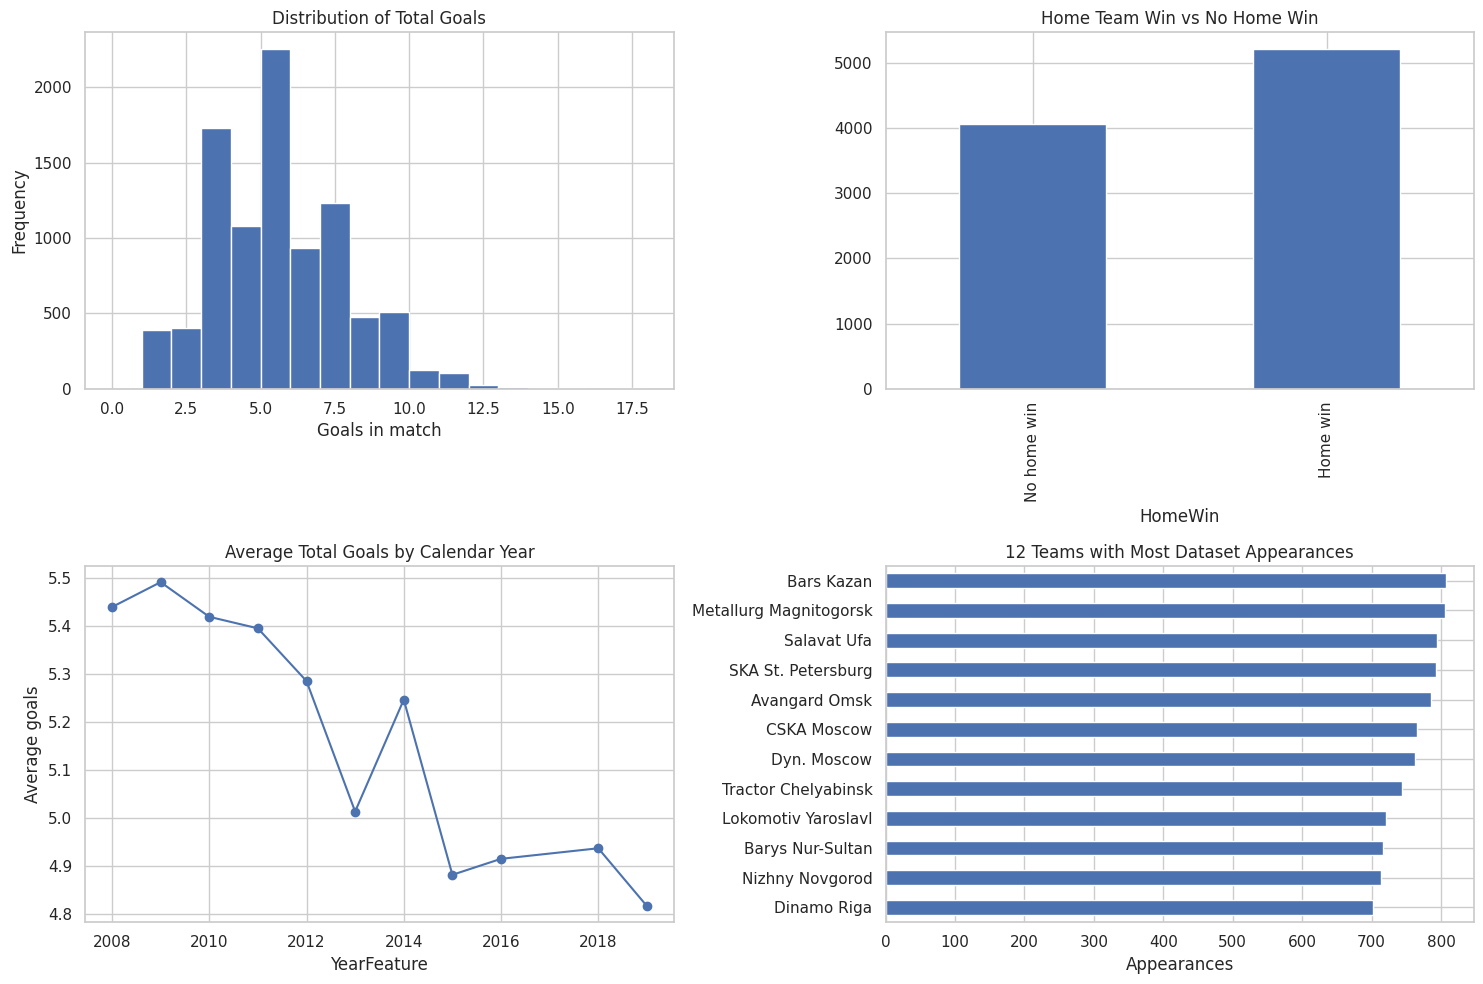

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

df["TotalGoals"].plot.hist(bins=range(0, int(df["TotalGoals"].max()) + 2), ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Total Goals")
axes[0, 0].set_xlabel("Goals in match")

df["HomeWin"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Home Team Win vs No Home Win")
axes[0, 1].set_xticks([0, 1], ["No home win", "Home win"])

goals_by_year = df.groupby("YearFeature")["TotalGoals"].mean()
goals_by_year.plot(marker="o", ax=axes[1, 0])
axes[1, 0].set_title("Average Total Goals by Calendar Year")
axes[1, 0].set_ylabel("Average goals")

top_teams = pd.concat([
    df["HOMETEAM"].value_counts().rename("matches"),
    df["AWAYTEAM"].value_counts().rename("matches")
], axis=1).fillna(0).sum(axis=1).sort_values(ascending=False).head(12)
top_teams.sort_values().plot(kind="barh", ax=axes[1, 1])
axes[1, 1].set_title("12 Teams with Most Dataset Appearances")
axes[1, 1].set_xlabel("Appearances")

plt.tight_layout()
plt.show()

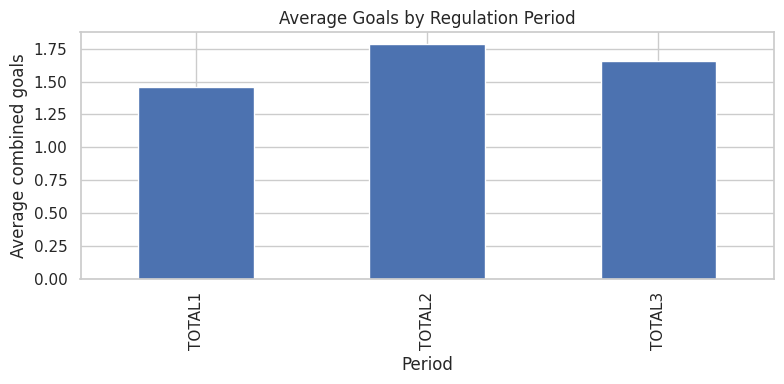

,matches,home_win_rate,average_total_goals
SEASON,,,
809,702,0.578,5.420
910,709,0.573,5.461
1011,678,0.560,5.540
1112,677,0.575,5.208
1213,762,0.552,5.281
1314,844,0.578,4.985
1415,920,0.549,5.176
1516,920,0.555,4.905
1617,944,0.577,4.954


In [16]:
period_cols = ["TOTAL1", "TOTAL2", "TOTAL3"]
available_period_cols = [c for c in period_cols if c in df.columns]
if available_period_cols:
    period_means = df[available_period_cols].mean()
    period_means.plot(kind="bar", figsize=(8, 4))
    plt.title("Average Goals by Regulation Period")
    plt.xlabel("Period")
    plt.ylabel("Average combined goals")
    plt.tight_layout()
    plt.show()

display(df.groupby("SEASON", dropna=False).agg(
    matches=("HomeWin", "size"),
    home_win_rate=("HomeWin", "mean"),
    average_total_goals=("TotalGoals", "mean")
).round(3).tail(15))

## 5. Build pre-match team-form features
For each match date, features are calculated from games dated **strictly before that date**. All games on the same date receive the same prior-history snapshot, preventing same-day results from leaking into another match on that date.

Features include each team's previous-game count, historical win rate, average goals scored, and average goals conceded. Team identities and calendar features are also included.

In [17]:
def add_pre_match_history(matches: pd.DataFrame) -> pd.DataFrame:
    data = matches.sort_values(["DATE", "HOMETEAM", "AWAYTEAM"]).copy()
    history = {}

    def empty_record():
        return {"games": 0, "wins": 0, "gf": 0.0, "ga": 0.0}

    feature_rows = []
    for date, group in data.groupby("DATE", sort=True):
        # Snapshot prior history for every match on this date before updating any team.
        for idx, row in group.iterrows():
            home = row["HOMETEAM"]
            away = row["AWAYTEAM"]
            h = history.get(home, empty_record())
            a = history.get(away, empty_record())

            feature_rows.append({
                "_row_index": idx,
                "home_games_prior": h["games"],
                "home_win_rate_prior": h["wins"] / h["games"] if h["games"] else np.nan,
                "home_avg_goals_for_prior": h["gf"] / h["games"] if h["games"] else np.nan,
                "home_avg_goals_against_prior": h["ga"] / h["games"] if h["games"] else np.nan,
                "away_games_prior": a["games"],
                "away_win_rate_prior": a["wins"] / a["games"] if a["games"] else np.nan,
                "away_avg_goals_for_prior": a["gf"] / a["games"] if a["games"] else np.nan,
                "away_avg_goals_against_prior": a["ga"] / a["games"] if a["games"] else np.nan,
            })

        # Update histories only after feature snapshots for the whole date have been made.
        for _, row in group.iterrows():
            home, away = row["HOMETEAM"], row["AWAYTEAM"]
            hg, ag = float(row["HG"]), float(row["AG"])
            if home not in history:
                history[home] = empty_record()
            if away not in history:
                history[away] = empty_record()
            history[home]["games"] += 1
            history[home]["wins"] += int(hg > ag)
            history[home]["gf"] += hg
            history[home]["ga"] += ag
            history[away]["games"] += 1
            history[away]["wins"] += int(ag > hg)
            history[away]["gf"] += ag
            history[away]["ga"] += hg

    feature_df = pd.DataFrame(feature_rows).set_index("_row_index")
    return data.join(feature_df, how="left")

model_df = add_pre_match_history(df)
history_features = [
    "home_games_prior", "home_win_rate_prior", "home_avg_goals_for_prior",
    "home_avg_goals_against_prior", "away_games_prior", "away_win_rate_prior",
    "away_avg_goals_for_prior", "away_avg_goals_against_prior"
]
display(model_df[["DATE", "HOMETEAM", "AWAYTEAM"] + history_features].head(10))

,DATE,HOMETEAM,AWAYTEAM,home_games_prior,home_win_rate_prior,home_avg_goals_for_prior,home_avg_goals_against_prior,away_games_prior,away_win_rate_prior,away_avg_goals_for_prior,away_avg_goals_against_prior
0,2008-09-02,Amur Khabarovsk,Dinamo Riga,0,NaN,NaN,NaN,0,NaN,NaN,NaN
1,2008-09-02,Metallurg Novokuznetsk,Din. Minsk,0,NaN,NaN,NaN,0,NaN,NaN,NaN
2,2008-09-02,Podolsk,MVD Balashikha,0,NaN,NaN,NaN,0,NaN,NaN,NaN
3,2008-09-02,Salavat Ufa,Lokomotiv Yaroslavl,0,NaN,NaN,NaN,0,NaN,NaN,NaN
4,2008-09-02,Sp. Moscow,Atlant Mytishi,0,NaN,NaN,NaN,0,NaN,NaN,NaN
5,2008-09-03,Amur Khabarovsk,Dinamo Riga,1,0.0,2.0,4.0,1,1.0,4.0,2.0
6,2008-09-03,Bars Kazan,Avangard Omsk,0,NaN,NaN,NaN,0,NaN,NaN,NaN
7,2008-09-03,Lada,Khimik,0,NaN,NaN,NaN,0,NaN,NaN,NaN
8,2008-09-03,Metallurg Magnitogorsk,SKA St. Petersburg,0,NaN,NaN,NaN,0,NaN,NaN,NaN
9,2008-09-03,Metallurg Novokuznetsk,Din. Minsk,1,0.0,4.0,5.0,1,1.0,5.0,4.0


## 6. Chronological train/test split
The oldest 80% of match dates are used for training and the newest 20% for testing. This better reflects forecasting future matches than a random split. Rows on the same date remain together.

In [18]:
unique_dates = np.sort(model_df["DATE"].unique())
cutoff_position = int(len(unique_dates) * 0.80)
cutoff_position = min(max(cutoff_position, 1), len(unique_dates) - 1)
cutoff_date = pd.Timestamp(unique_dates[cutoff_position])

train_df = model_df[model_df["DATE"] < cutoff_date].copy()
test_df = model_df[model_df["DATE"] >= cutoff_date].copy()

feature_cols = [
    "HOMETEAM", "AWAYTEAM", "SEASON", "YearFeature", "MonthFeature", "DayOfWeek",
    *history_features
]
target_col = "HomeWin"

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

categorical_features = ["HOMETEAM", "AWAYTEAM"]
numeric_features = [c for c in feature_cols if c not in categorical_features]

print(f"Training matches: {len(train_df):,} | Test matches: {len(test_df):,}")
print(f"Training dates: {train_df['DATE'].min().date()} to {train_df['DATE'].max().date()}")
print(f"Test dates: {test_df['DATE'].min().date()} to {test_df['DATE'].max().date()}")

Training matches: 6,989 | Test matches: 2,293
Training dates: 2008-09-02 to 2018-01-15
Test dates: 2018-01-16 to 2019-12-09


## 7. Train and compare models
Both models use preprocessing pipelines so missing historical values are imputed using training data only. Team names are one-hot encoded; numeric features are imputed and scaled for Logistic Regression.

In [19]:
numeric_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_preprocess, numeric_features),
    ("cat", categorical_preprocess, categorical_features)
])

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocess", ColumnTransformer(transformers=[
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), categorical_features)
        ])),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

results = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    pred = model.predict(X_test)
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    }
    if hasattr(model, "predict_proba") and len(np.unique(y_test)) == 2:
        row["ROC_AUC"] = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    else:
        row["ROC_AUC"] = np.nan
    results.append(row)

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,Random Forest,0.6171,0.6344,0.7169,0.6731,0.6531
0,Logistic Regression,0.5905,0.6443,0.5702,0.6050,0.6408


## 8. Evaluate the best model
Accuracy alone can hide uneven performance. Review precision, recall, F1-score, ROC-AUC, and the confusion matrix together. Use the actual results from your run rather than claiming a target accuracy in advance.

Selected model by test F1: Random Forest

Classification report:
              precision    recall  f1-score   support

 No home win       0.59      0.50      0.54      1032
    Home win       0.63      0.72      0.67      1261

    accuracy                           0.62      2293
   macro avg       0.61      0.61      0.61      2293
weighted avg       0.61      0.62      0.61      2293



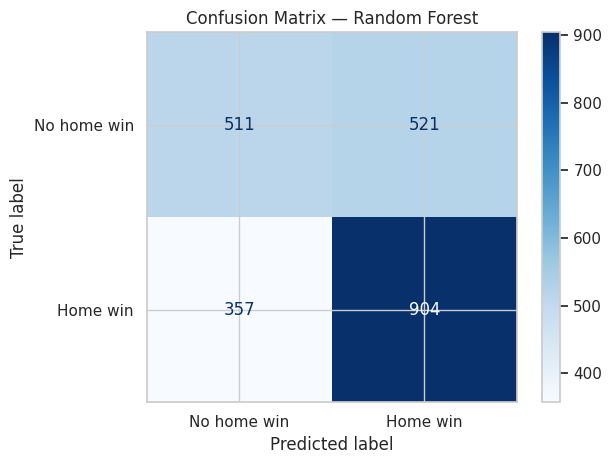

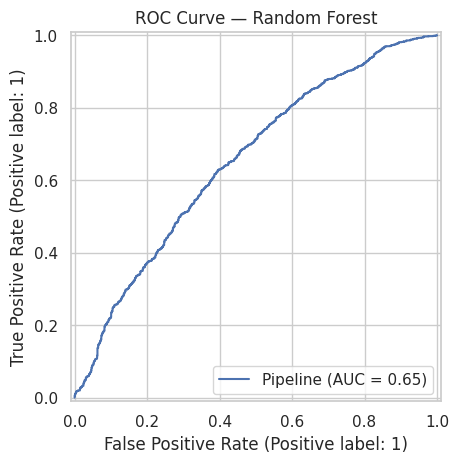

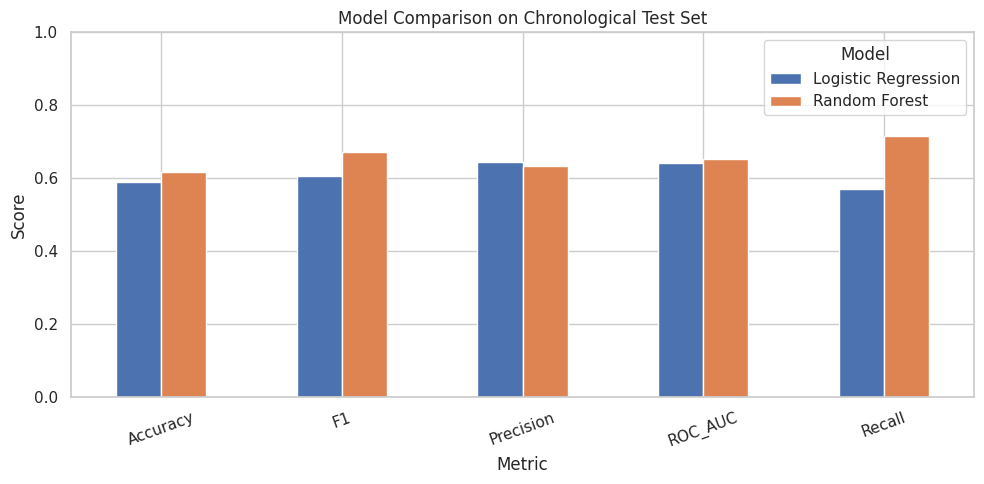

In [20]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)

print("Selected model by test F1:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, target_names=["No home win", "Home win"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["No home win", "Home win"], cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

if hasattr(best_model, "predict_proba") and len(np.unique(y_test)) == 2:
    RocCurveDisplay.from_estimator(best_model, X_test, y_test)
    plt.title(f"ROC Curve — {best_name}")
    plt.show()

results_long = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
pivot = results_long.pivot(index="Metric", columns="Model", values="Score")
pivot.plot(kind="bar", figsize=(10, 5))
plt.ylim(0, 1)
plt.title("Model Comparison on Chronological Test Set")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 9. Inspect predictions
This table compares a sample of test-set predictions with actual outcomes. Probabilities are model estimates, not certainty.

In [21]:
prediction_output = test_df[["DATE", "HOMETEAM", "AWAYTEAM", "HG", "AG", "HomeWin"]].copy()
prediction_output["PredictedHomeWin"] = best_pred
if hasattr(best_model, "predict_proba"):
    prediction_output["HomeWinProbability"] = best_model.predict_proba(X_test)[:, 1].round(3)
prediction_output["Correct"] = prediction_output["HomeWin"] == prediction_output["PredictedHomeWin"]
display(prediction_output.head(20))

,DATE,HOMETEAM,AWAYTEAM,HG,AG,HomeWin,PredictedHomeWin,HomeWinProbability,Correct
6989,2018-01-16,Amur Khabarovsk,Jokerit,3,2,1,0,0.309,False
6990,2018-01-16,Avangard Omsk,Metallurg Magnitogorsk,3,4,0,0,0.325,True
6991,2018-01-16,Barys Nur-Sultan,Salavat Ufa,4,3,1,0,0.470,False
6992,2018-01-16,Cherepovets,Nizhny Novgorod,3,4,0,0,0.348,True
6993,2018-01-16,Din. Minsk,Amur Khabarovsk,0,2,0,1,0.645,False
6994,2018-01-16,Dyn. Moscow,Bars Kazan,1,2,0,0,0.478,True
6995,2018-01-16,Dyn. Moscow,Kunlun,5,2,1,1,0.742,True
6996,2018-01-16,HC Yugra,Tractor Chelyabinsk,0,4,0,0,0.410,True
6997,2018-01-16,Kunlun,Dinamo Riga,3,4,0,1,0.571,False
6998,2018-01-16,Lada,Barys Nur-Sultan,4,3,1,0,0.465,False


## 10. Key findings and responsible interpretation
Run the notebook from top to bottom, then complete this section using your measured results.

- **Data coverage:** The dataset spans multiple seasons and contains match-level outcomes and period scoring.
- **Home advantage:** Compare the home-win rate with the overall outcome distribution; do not assume it is constant across teams or seasons.
- **Scoring patterns:** Use the EDA charts to describe the typical total goals and differences by year/period.
- **Model performance:** Report the actual test metrics and compare models against a simple baseline (always predicting the majority class).
- **Limitations:** No player lineups, injuries, goalie information, travel/rest days, odds, or richer pre-game context are included. Historical team names may change, and old seasons may not represent current team strength.
- **Future work:** Add a majority-class baseline, calibration, rolling-window validation, team-specific home/away form, recent-form windows, and external game-context data where licensing permits.

### Suggested conclusion template
> The project demonstrates an end-to-end sports analytics workflow, from data quality checks and exploratory visualization to leakage-aware feature engineering and chronological model evaluation. The best model should be selected based on the measured test metrics and the intended use case, not on training performance alone.

## 11. Export outputs
The following cell saves key tables and a prediction file for GitHub/portfolio use. Generated output files are not committed automatically; review them first.

In [22]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
results_df.to_csv(output_dir / "model_comparison.csv", index=False)
prediction_output.to_csv(output_dir / "test_predictions.csv", index=False)
df.describe(include="all").to_csv(output_dir / "dataset_summary.csv")
print("Saved outputs to:", output_dir.resolve())

Saved outputs to: /content/outputs
